In [1]:
import findspark
from pyspark.sql import SparkSession
findspark.init()

In [2]:
!pip install --upgrade numpy pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable


In [3]:
import pandas

In [4]:
print(pandas.__version__)

2.3.3


In [5]:
spark = SparkSession.builder \
    .appName("Reddit_DB__Analysis") \
    .master("spark://192.168.2.111:7077") \
    .config("spark.executor.instances", "3") \
    .config("spark.executor.cores", "2") \
    .config("spark.executor.memory", "2g") \
    .config("spark.driver.memory", "1g") \
    .getOrCreate()

print("Connected to PySpark")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/03/11 18:00:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Connected to PySpark


In [6]:
# The standard HDFS port is 9000 (sometimes 8020 depending on your Hadoop config)
# We use the internal IP that worked for Spark
hdfs_namenode_ip = "192.168.2.111" 
hdfs_port = "9000"
hdfs_path = f"hdfs://{hdfs_namenode_ip}:{hdfs_port}/user/ubuntu/reddit-db"

print(f"Attempting to read from: {hdfs_path}")

try:
    # Assuming the data is in JSON format. 
    # If it is Parquet, change .json() to .parquet()
    # If it is CSV, change .json() to .csv(header=True, inferSchema=True)
    df = spark.read.json(hdfs_path)
    
    # Check how many partitions the data was split into across your workers
    num_partitions = df.rdd.getNumPartitions()
    print(f"Success! Data loaded into {num_partitions} distributed partitions.")
    
    # Print the schema to see the columns and data types
    print("\nData Schema:")
    df.printSchema()

except Exception as e:
    print(f"Error reading from HDFS: {e}")

Attempting to read from: hdfs://192.168.2.111:9000/user/ubuntu/reddit-db


Success! Data loaded into 147 distributed partitions.

Data Schema:
root
 |-- author: string (nullable = true)
 |-- body: string (nullable = true)
 |-- content: string (nullable = true)
 |-- content_len: long (nullable = true)
 |-- id: string (nullable = true)
 |-- normalizedBody: string (nullable = true)
 |-- subreddit: string (nullable = true)
 |-- subreddit_id: string (nullable = true)
 |-- summary: string (nullable = true)
 |-- summary_len: long (nullable = true)
 |-- title: string (nullable = true)



In [7]:
from pyspark.sql.functions import col, lower, split, explode, regexp_replace, desc

In [8]:
# 1. Clean the text: lower case and remove punctuation
# This regex replaces anything that is NOT a word character or whitespace with nothing
cleaned_text = regexp_replace(lower(col("body")), r"[^\w\s]", "")

# 2. Split the text into an array of words based on spaces
words_array = split(cleaned_text, r"\s+")

# 3. Explode the array so each word gets its own row, and filter out empty strings
words_df = df.select(explode(words_array).alias("word")) \
             .filter(col("word") != "")

# 4. Group by word, count them, and sort from most frequent to least frequent
word_frequencies = words_df.groupBy("word") \
                           .count() \
                           .orderBy(desc("count"))

print("Spark transformation plan created. Ready to compute!")

Spark transformation plan created. Ready to compute!


In [9]:
# This triggers the actual calculation across your cluster. 
# It might take a minute depending on how large your database is!
print("Crunching numbers across the cluster... Please wait.")

# Limit to top 10,000 and convert to a local Pandas DataFrame
top_words_pd = word_frequencies.limit(10000).toPandas()

print("Successfully brought the top 10,000 words back to Jupyter!")
top_words_pd.head(10) # Let's peek at the most common words

Crunching numbers across the cluster... Please wait.


Successfully brought the top 10,000 words back to Jupyter!


,word,count
0,the,41646171
1,i,36482074
2,to,35337887
3,and,33479605
4,a,28114552
5,of,19949647
6,that,15224006
7,in,14701543
8,it,14118021
9,my,12730468


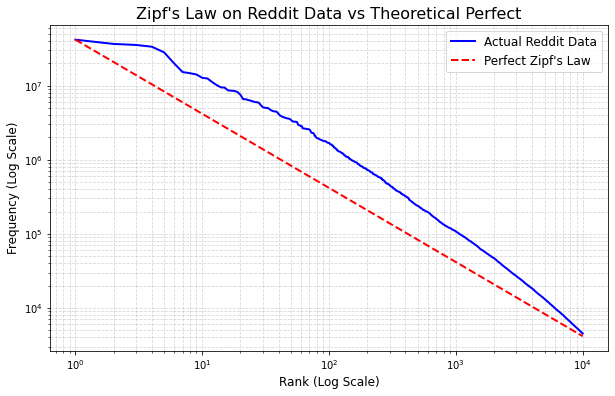

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Create a new column for the Rank (1, 2, 3... up to the length of the dataframe)
top_words_pd['rank'] = np.arange(1, len(top_words_pd) + 1)

# --- NEW: Calculate the theoretical perfect Zipf line ---
# Get the frequency of the #1 most common word
max_frequency = top_words_pd['count'].max()

# Calculate expected frequencies: (Max Frequency) / Rank
top_words_pd['theoretical_zipf'] = max_frequency / top_words_pd['rank']
# --------------------------------------------------------

# Set up the plot
plt.figure(figsize=(10, 6))

# Plot 1: Actual Reddit Data (Rank vs Count)
plt.plot(top_words_pd['rank'], top_words_pd['count'], color='blue', linewidth=2, label='Actual Reddit Data')

# --- NEW: Plot 2: The Theoretical Line ---
plt.plot(top_words_pd['rank'], top_words_pd['theoretical_zipf'], color='red', linestyle='--', linewidth=2, label="Perfect Zipf's Law")
# -----------------------------------------

# Zipf's law requires both axes to be on a logarithmic scale
plt.xscale('log')
plt.yscale('log')

# Labels and styling
plt.title("Zipf's Law on Reddit Data vs Theoretical Perfect", fontsize=16)
plt.xlabel("Rank (Log Scale)", fontsize=12)
plt.ylabel("Frequency (Log Scale)", fontsize=12)
plt.grid(True, which="both", ls="--", alpha=0.5)

# --- NEW: Add a legend so we know which line is which ---
plt.legend(fontsize=12)
# --------------------------------------------------------

# Show the plot
plt.show()